In [ ]:
!pip install -q matplotlib seaborn scikit-learn

In [ ]:
import os
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
!cp -r '/content/drive/MyDrive/Colab Notebooks/food_dataset_complete_two' /content/food_dataset_complete_two

In [ ]:
import os

DATASET_DIR = "/content/drive/MyDrive/Colab Notebooks/food_dataset_complete_two"

TRAIN_DIR = os.path.join(DATASET_DIR, 'train')
VALIDATE_DIR = os.path.join(DATASET_DIR, 'val')
TEST_DIR = os.path.join(DATASET_DIR, 'test')

print("=======Dataset Summary=======")

for split in ['train', 'val', 'test']:
    print("\n", split)

    path = os.path.join(DATASET_DIR, split)

    for cls in os.listdir(path):
        cls_path = os.path.join(path, cls)


        if not os.path.isdir(cls_path):
            continue

        count = len(os.listdir(cls_path))
        print(cls, ":", count, "photo")

=======Dataset Summary=======

 train
larbbeef : 99 photo
pad kra pao beef : 80 photo
chicken green curry : 100 photo
larbchicken : 103 photo
panangbeef : 87 photo
tom yum kung nam sai : 81 photo
massamancurrybeef : 77 photo
pad thai pork : 80 photo
tom yum kung nam kon : 100 photo
pad kra pao mince pork : 120 photo
pad kra pao crispy pork : 80 photo
panangpork : 112 photo
beef green curry : 80 photo
tom yum seafood : 92 photo
tomkhagai : 117 photo
pad thai chicken : 88 photo
gaeng_som_cha_om_kung : 120 photo
massamancurrychicken : 93 photo
larbpork : 118 photo
gaengsomkung : 88 photo
som tum thai : 80 photo
som tum poo plara : 120 photo
panangchicken : 87 photo
gaengsomfish : 88 photo
pad thai goong : 132 photo
tom yum pla : 92 photo

 val
larbchicken : 13 photo
larbbeef : 12 photo
pad kra pao beef : 10 photo
massamancurrybeef : 10 photo
tom yum kung nam sai : 10 photo
chicken green curry : 13 photo
tom yum kung nam kon : 13 photo
panangbeef : 11 photo
pad kra pao mince pork : 15 phot

In [ ]:
IMG_SIZE = 224           #  ใช้ 224x224
BATCH_SIZE  = 32         # แบ่งรูปเทรนต่อรอบ
EPOCHS_TOP  = 30
EPOCHS_FINE = 20         # Fine-tune ทั้ง model
LR_TOP      = 5e-4       # Learning rate ช่วงแรก
LR_FINE     = 1e-4       # Learning rate ช่วง fine-tune
MODEL_PATH = '/content/food_classifier_efficientnetb0.h5'

CLASS_NAME = [
    'beef green curry',
    'chicken green curry',
    'gaeng_som_cha_om_kung',
    'gaengsomfish',
    'gaengsomkung',
    'larbbeef',
    'larbchicken',
    'larbpork',
    'massamancurrybeef',
    'massamancurrychicken',
    'pad kra pao beef',
    'pad kra pao crispy pork',
    'pad kra pao mince pork',
    'pad thai chicken',
    'pad thai goong',
    'pad thai pork',
    'panangbeef',
    'panangchicken',
    'panangpork',
    'som tum poo plara',
    'som tum thai',
    'tom yum kung nam kon',
    'tom yum kung nam sai',
    'tom yum pla',
    'tom yum seafood',
    'tomkhagai'
]

NUM_CLASS = len(CLASS_NAME)

print("=======Config=======")
print(f' Image size  : {IMG_SIZE}x{IMG_SIZE}')
print(f' Batch size : {BATCH_SIZE}')
print(f' Epochs top : {EPOCHS_TOP}')
print(f' Epochs fine: {EPOCHS_FINE}')
print(f' Learning rate top : {LR_TOP}')
print(f' Learning rate fine: {LR_FINE}')
print(f' Amout Class  : {NUM_CLASS}')
print(f' Class name : {CLASS_NAME}')

=======Config=======
 Image size  : 224x224
 Batch size : 32
 Epochs top : 30
 Epochs fine: 20
 Learning rate top : 0.0005
 Learning rate fine: 0.0001
 Amout Class  : 26
 Class name : ['beef green curry', 'chicken green curry', 'gaeng_som_cha_om_kung', 'gaengsomfish', 'gaengsomkung', 'larbbeef', 'larbchicken', 'larbpork', 'massamancurrybeef', 'massamancurrychicken', 'pad kra pao beef', 'pad kra pao crispy pork', 'pad kra pao mince pork', 'pad thai chicken', 'pad thai goong', 'pad thai pork', 'panangbeef', 'panangchicken', 'panangpork', 'som tum poo plara', 'som tum thai', 'tom yum kung nam kon', 'tom yum kung nam sai', 'tom yum pla', 'tom yum seafood', 'tomkhagai']


In [ ]:
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications.efficientnet import preprocess_input
import os

TEST_DIR = os.path.join(DATASET_DIR, 'test')

train_data = ImageDataGenerator(
    preprocessing_function = preprocess_input,
    rotation_range = 20,
    width_shift_range = 0.2,
    height_shift_range = 0.2,
    shear_range = 0.2,
    zoom_range = 0.2,
    horizontal_flip = True,
    brightness_range = [0.8, 1.2],
    fill_mode = 'nearest'
)

val_data = ImageDataGenerator(
    preprocessing_function = preprocess_input
)

test_data = ImageDataGenerator(
    preprocessing_function = preprocess_input
)

# load
train_loader = train_data.flow_from_directory(
    TRAIN_DIR,
    target_size = (IMG_SIZE, IMG_SIZE),
    batch_size = BATCH_SIZE,
    class_mode = 'categorical',
    shuffle=True
)

val_loader = val_data.flow_from_directory(
    VALIDATE_DIR,
    target_size = (IMG_SIZE, IMG_SIZE),
    batch_size = BATCH_SIZE,
    class_mode = 'categorical',
    shuffle = False
)

test_loader = test_data.flow_from_directory(
    TEST_DIR,
    target_size = (IMG_SIZE, IMG_SIZE),
    batch_size = BATCH_SIZE,
    class_mode = 'categorical',
    shuffle = False
)

print('Class indices:', train_loader.class_indices)

Found 2513 images belonging to 26 classes.
Found 316 images belonging to 26 classes.
Found 322 images belonging to 26 classes.
Class indices: {'beef green curry': 0, 'chicken green curry': 1, 'gaeng_som_cha_om_kung': 2, 'gaengsomfish': 3, 'gaengsomkung': 4, 'larbbeef': 5, 'larbchicken': 6, 'larbpork': 7, 'massamancurrybeef': 8, 'massamancurrychicken': 9, 'pad kra pao beef': 10, 'pad kra pao crispy pork': 11, 'pad kra pao mince pork': 12, 'pad thai chicken': 13, 'pad thai goong': 14, 'pad thai pork': 15, 'panangbeef': 16, 'panangchicken': 17, 'panangpork': 18, 'som tum poo plara': 19, 'som tum thai': 20, 'tom yum kung nam kon': 21, 'tom yum kung nam sai': 22, 'tom yum pla': 23, 'tom yum seafood': 24, 'tomkhagai': 25}


In [ ]:
import tensorflow as tf

from tensorflow.keras.applications import EfficientNetB0
from tensorflow.keras import layers, models

base_model = EfficientNetB0(
    weights='imagenet',
    include_top=False,
    input_shape=(IMG_SIZE, IMG_SIZE, 3)
)

base_model.trainable = False

features = base_model.output
x = layers.GlobalAveragePooling2D()(features)
x = layers.Dense(256, activation='relu')(x)
x = layers.Dropout(0.3)(x)

predictions = layers.Dense(NUM_CLASS, activation='softmax')(x)
food_model = models.Model(inputs=base_model.input, outputs=predictions)

food_model.summary()

16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ rescaling           │ (None, 224, 224,  │          0 │ input_layer[0][0] │
│ (Rescaling)         │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ normalization       │ (None, 224, 224,  │          7 │ rescaling[0][0]   │
│ (Normalization)     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ rescaling_1         │ (None, 224, 224,  │          0 │ normalization[0]… │
│ (Rescaling)         │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_conv_pad       │ (None, 225, 225,  │          0 │ rescaling_1[0][0] │
│ (ZeroPadding2D)     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_conv (Conv2D)  │ (None, 112, 112,  │        864 │ stem_conv_pad[0]… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_bn             │ (None, 112, 112,  │        128 │ stem_conv[0][0]   │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_activation     │ (None, 112, 112,  │          0 │ stem_bn[0][0]     │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_dwconv      │ (None, 112, 112,  │        288 │ stem_activation[… │
│ (DepthwiseConv2D)   │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_bn          │ (None, 112, 112,  │        128 │ block1a_dwconv[0… │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_activation  │ (None, 112, 112,  │          0 │ block1a_bn[0][0]  │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_squeeze  │ (None, 32)        │          0 │ block1a_activati… │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_reshape  │ (None, 1, 1, 32)  │          0 │ block1a_se_squee… │
│ (Reshape)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_reduce   │ (None, 1, 1, 8)   │        264 │ block1a_se_resha… │
│ (Conv2D)            │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_expand   │ (None, 1, 1, 32)  │        288 │ block1a_se_reduc… │
│ (Conv2D)            │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_excite   │ (None, 112, 112,  │          0 │ block1a_activati… │
│ (Multiply)          │ 32)               │            │ block1a_se_expan… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_project_co… │ (None, 112, 112,  │        512 │ block1a_se_excit

 Total params: 4,384,189 (16.72 MB)

 Trainable params: 334,618 (1.28 MB)

 Non-trainable params: 4,049,571 (15.45 MB)

# **TRAIN**

In [ ]:
import tensorflow as tf

food_model.compile (
    optimizer=tf.keras.optimizers.Adam(learning_rate=LR_TOP),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

save_best = tf.keras.callbacks.ModelCheckpoint (
    MODEL_PATH,
    monitor='val_accuracy',
    save_best_only=True,
)

stop_early = tf.keras.callbacks.EarlyStopping (
    monitor='val_loss',
    patience=5,
    restore_best_weights=True,
)

reduce_lr = tf.keras.callbacks.ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.3,
    patience=2,
    verbose=1
)

print("=======Start Training=======")

train_result = food_model.fit (
    train_loader,
    validation_data = val_loader,
    epochs = EPOCHS_TOP,
    callbacks = [save_best, stop_early, reduce_lr]
)


=======Start Training=======
Epoch 1/30
 7/79 ━━━━━━━━━━━━━━━━━━━━ 38s 533ms/step - accuracy: 0.0391 - loss: 3.3468

/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


79/79 ━━━━━━━━━━━━━━━━━━━━ 0s 866ms/step - accuracy: 0.1720 - loss: 2.8957

79/79 ━━━━━━━━━━━━━━━━━━━━ 121s 1s/step - accuracy: 0.2678 - loss: 2.5242 - val_accuracy: 0.4747 - val_loss: 1.7747 - learning_rate: 5.0000e-04
Epoch 2/30
79/79 ━━━━━━━━━━━━━━━━━━━━ 0s 680ms/step - accuracy: 0.5230 - loss: 1.6267

79/79 ━━━━━━━━━━━━━━━━━━━━ 57s 719ms/step - accuracy: 0.5300 - loss: 1.5387 - val_accuracy: 0.5443 - val_loss: 1.3371 - learning_rate: 5.0000e-04
Epoch 3/30
79/79 ━━━━━━━━━━━━━━━━━━━━ 0s 676ms/step - accuracy: 0.6138 - loss: 1.2603

...

79/79 ━━━━━━━━━━━━━━━━━━━━ 59s 750ms/step - accuracy: 0.7012 - loss: 0.8896 - val_accuracy: 0.6297 - val_loss: 1.0360 - learning_rate: 5.0000e-04
Epoch 7/30
79/79 ━━━━━━━━━━━━━━━━━━━━ 58s 731ms/step - accuracy: 0.7318 - loss: 0.8153 - val_accuracy: 0.6234 - val_loss: 1.0538 - learning_rate: 5.0000e-04
Epoch 8/30
79/79 ━━━━━━━━━━━━━━━━━━━━ 57s 718ms/step - accuracy: 0.7493 - loss: 0.7497 - val_accuracy: 0.6234 - val_loss: 1.0126 - learning_rate: 5.0000e-04
Epoch 9/30
79/79 ━━━━━━━━━━━━━━━━━━━━ 0s 663ms/step - accuracy: 0.7558 - loss: 0.7223

79/79 ━━━━━━━━━━━━━━━━━━━━ 58s 736ms/step - accuracy: 0.7596 - loss: 0.7206 - val_accuracy: 0.6487 - val_loss: 0.9725 - learning_rate: 5.0000e-04
Epoch 10/30
79/79 ━━━━━━━━━━━━━━━━━━━━ 0s 674ms/step - accuracy: 0.7721 - loss: 0.6830

79/79 ━━━━━━━━━━━━━━━━━━━━ 57s 720ms/step - accuracy: 0.7752 - loss: 0.6825 - val_accuracy: 0.6614 - val_loss: 0.9481 - learning_rate: 5.0000e-04
Epoch 11/30
79/79 ━━━━━━━━━━━━━━━━━━━━ 57s 719ms/step - accuracy: 0.7859 - loss: 0.6351 - val_accuracy: 0.6139 - val_loss: 0.9744 - learning_rate: 5.0000e-04
Epoch 12/30
79/79 ━━━━━━━━━━━━━━━━━━━━ 56s 704ms/step - accuracy: 0.8142 - loss: 0.5806 - val_accuracy: 0.6487 - val_loss: 0.9145 - learning_rate: 5.0000e-04
Epoch 13/30
79/79 ━━━━━━━━━━━━━━━━━━━━ 55s 687ms/step - accuracy: 0.8090 - loss: 0.5718 - val_accuracy: 0.6329 - val_loss: 0.9566 - learning_rate: 5.0000e-04
Epoch 14/30
79/79 ━━━━━━━━━━━━━━━━━━━━ 0s 650ms/step - accuracy: 0.8143 - loss: 0.5704
Epoch 14: ReduceLROnPlateau reducing learning rate to 0.0001500000071246177.
79/79 ━━━━━━━━━━━━━━━━━━━━ 81s 684ms/step - accuracy: 0.8233 - loss: 0.5432 - val_accuracy: 0.6519 - val_loss: 0.9180 - learning_rate: 5.0000e-04
Epoch 15/30
79/79 ━━━━━━━━━━━━━━━━━━━━ 0s 655ms/step - accuracy: 0.834

79/79 ━━━━━━━━━━━━━━━━━━━━ 55s 690ms/step - accuracy: 0.8345 - loss: 0.5053 - val_accuracy: 0.6741 - val_loss: 0.9004 - learning_rate: 1.5000e-04
Epoch 16/30
79/79 ━━━━━━━━━━━━━━━━━━━━ 54s 683ms/step - accuracy: 0.8368 - loss: 0.4863 - val_accuracy: 0.6709 - val_loss: 0.9115 - learning_rate: 1.5000e-04
Epoch 17/30
79/79 ━━━━━━━━━━━━━━━━━━━━ 0s 648ms/step - accuracy: 0.8610 - loss: 0.4575
Epoch 17: ReduceLROnPlateau reducing learning rate to 4.500000213738531e-05.
79/79 ━━━━━━━━━━━━━━━━━━━━ 54s 679ms/step - accuracy: 0.8420 - loss: 0.4857 - val_accuracy: 0.6709 - val_loss: 0.9056 - learning_rate: 1.5000e-04
Epoch 18/30
79/79 ━━━━━━━━━━━━━━━━━━━━ 0s 667ms/step - accuracy: 0.8620 - loss: 0.4501

79/79 ━━━━━━━━━━━━━━━━━━━━ 56s 713ms/step - accuracy: 0.8548 - loss: 0.4644 - val_accuracy: 0.6804 - val_loss: 0.8968 - learning_rate: 4.5000e-05
Epoch 19/30
79/79 ━━━━━━━━━━━━━━━━━━━━ 56s 709ms/step - accuracy: 0.8587 - loss: 0.4558 - val_accuracy: 0.6646 - val_loss: 0.8919 - learning_rate: 4.5000e-05
Epoch 20/30
79/79 ━━━━━━━━━━━━━━━━━━━━ 52s 662ms/step - accuracy: 0.8500 - loss: 0.4537 - val_accuracy: 0.6709 - val_loss: 0.8873 - learning_rate: 4.5000e-05
Epoch 21/30
79/79 ━━━━━━━━━━━━━━━━━━━━ 54s 683ms/step - accuracy: 0.8583 - loss: 0.4456 - val_accuracy: 0.6709 - val_loss: 0.8908 - learning_rate: 4.5000e-05
Epoch 22/30
79/79 ━━━━━━━━━━━━━━━━━━━━ 0s 648ms/step - accuracy: 0.8555 - loss: 0.4544
Epoch 22: ReduceLROnPlateau reducing learning rate to 1.3500000204658135e-05.
79/79 ━━━━━━━━━━━━━━━━━━━━ 53s 677ms/step - accuracy: 0.8603 - loss: 0.4419 - val_accuracy: 0.6772 - val_loss: 0.8876 - learning_rate: 4.5000e-05
Epoch 23/30
79/79 ━━━━━━━━━━━━━━━━━━━━ 54s 684ms/step - accuracy: 0.8

# **Finetune**

In [ ]:
base_model.trainable = True

food_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=LR_FINE),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

print("=======Start Fine-tuning=======")

fine_result = food_model.fit(
    train_loader,
    validation_data=val_loader,
    epochs=EPOCHS_FINE,
    callbacks=[save_best, stop_early, reduce_lr]
)

=======Start Fine-tuning=======
Epoch 1/20
79/79 ━━━━━━━━━━━━━━━━━━━━ 189s 1s/step - accuracy: 0.5690 - loss: 1.3300 - val_accuracy: 0.6108 - val_loss: 1.1278 - learning_rate: 1.0000e-04
Epoch 2/20
79/79 ━━━━━━━━━━━━━━━━━━━━ 0s 707ms/step - accuracy: 0.7287 - loss: 0.8466
Epoch 2: ReduceLROnPlateau reducing learning rate to 2.9999999242136255e-05.
79/79 ━━━━━━━━━━━━━━━━━━━━ 103s 739ms/step - accuracy: 0.7370 - loss: 0.8060 - val_accuracy: 0.6551 - val_loss: 0.9383 - learning_rate: 1.0000e-04
Epoch 3/20
79/79 ━━━━━━━━━━━━━━━━━━━━ 0s 736ms/step - accuracy: 0.7914 - loss: 0.6231

79/79 ━━━━━━━━━━━━━━━━━━━━ 62s 782ms/step - accuracy: 0.7883 - loss: 0.6301 - val_accuracy: 0.6930 - val_loss: 0.8767 - learning_rate: 3.0000e-05
Epoch 4/20
79/79 ━━━━━━━━━━━━━━━━━━━━ 59s 737ms/step - accuracy: 0.8142 - loss: 0.5688 - val_accuracy: 0.6772 - val_loss: 0.8673 - learning_rate: 3.0000e-05
Epoch 5/20
79/79 ━━━━━━━━━━━━━━━━━━━━ 60s 757ms/step - accuracy: 0.8205 - loss: 0.5294 - val_accuracy: 0.6835 - val_loss: 0.8641 - learning_rate: 3.0000e-05
Epoch 6/20
79/79 ━━━━━━━━━━━━━━━━━━━━ 59s 739ms/step - accuracy: 0.8372 - loss: 0.5124 - val_accuracy: 0.6772 - val_loss: 0.8531 - learning_rate: 3.0000e-05
Epoch 7/20
79/79 ━━━━━━━━━━━━━━━━━━━━ 59s 741ms/step - accuracy: 0.8468 - loss: 0.4800 - val_accuracy: 0.6899 - val_loss: 0.8248 - learning_rate: 3.0000e-05
Epoch 8/20
79/79 ━━━━━━━━━━━━━━━━━━━━ 0s 699ms/step - accuracy: 0.8481 - loss: 0.4383

79/79 ━━━━━━━━━━━━━━━━━━━━ 59s 742ms/step - accuracy: 0.8480 - loss: 0.4329 - val_accuracy: 0.6962 - val_loss: 0.8084 - learning_rate: 3.0000e-05
Epoch 9/20
79/79 ━━━━━━━━━━━━━━━━━━━━ 58s 728ms/step - accuracy: 0.8786 - loss: 0.4005 - val_accuracy: 0.6835 - val_loss: 0.8210 - learning_rate: 3.0000e-05
Epoch 10/20
79/79 ━━━━━━━━━━━━━━━━━━━━ 59s 743ms/step - accuracy: 0.8667 - loss: 0.4024 - val_accuracy: 0.6899 - val_loss: 0.8060 - learning_rate: 3.0000e-05
Epoch 11/20
79/79 ━━━━━━━━━━━━━━━━━━━━ 60s 757ms/step - accuracy: 0.8770 - loss: 0.3897 - val_accuracy: 0.6930 - val_loss: 0.7793 - learning_rate: 3.0000e-05
Epoch 12/20
79/79 ━━━━━━━━━━━━━━━━━━━━ 61s 772ms/step - accuracy: 0.8894 - loss: 0.3526 - val_accuracy: 0.6962 - val_loss: 0.7767 - learning_rate: 3.0000e-05
Epoch 13/20
79/79 ━━━━━━━━━━━━━━━━━━━━ 0s 702ms/step - accuracy: 0.8768 - loss: 0.3545

79/79 ━━━━━━━━━━━━━━━━━━━━ 59s 749ms/step - accuracy: 0.8898 - loss: 0.3324 - val_accuracy: 0.7215 - val_loss: 0.7563 - learning_rate: 3.0000e-05
Epoch 14/20
79/79 ━━━━━━━━━━━━━━━━━━━━ 59s 742ms/step - accuracy: 0.8938 - loss: 0.3307 - val_accuracy: 0.7152 - val_loss: 0.7592 - learning_rate: 3.0000e-05
Epoch 15/20
79/79 ━━━━━━━━━━━━━━━━━━━━ 0s 718ms/step - accuracy: 0.9051 - loss: 0.2856
Epoch 15: ReduceLROnPlateau reducing learning rate to 8.999999772640877e-06.
79/79 ━━━━━━━━━━━━━━━━━━━━ 59s 747ms/step - accuracy: 0.9069 - loss: 0.2940 - val_accuracy: 0.7184 - val_loss: 0.7567 - learning_rate: 3.0000e-05
Epoch 16/20
79/79 ━━━━━━━━━━━━━━━━━━━━ 58s 730ms/step - accuracy: 0.9113 - loss: 0.2886 - val_accuracy: 0.7120 - val_loss: 0.7568 - learning_rate: 9.0000e-06
Epoch 17/20
79/79 ━━━━━━━━━━━━━━━━━━━━ 59s 747ms/step - accuracy: 0.9168 - loss: 0.2757 - val_accuracy: 0.7215 - val_loss: 0.7540 - learning_rate: 9.0000e-06
Epoch 18/20
79/79 ━━━━━━━━━━━━━━━━━━━━ 60s 760ms/step - accuracy: 0.92

In [ ]:
print("=======Testing=======")

test_loss, test_acc = food_model.evaluate(test_loader)

print("Test accuracy :", test_acc)
print("Test loss :", test_loss)

=======Testing=======
11/11 ━━━━━━━━━━━━━━━━━━━━ 13s 1s/step - accuracy: 0.7671 - loss: 0.6830
Test accuracy : 0.7670807242393494
Test loss : 0.683014988899231


In [ ]:
import json
from google.colab import files

# =====SAVE METRICS=====
save_training_result = {
    'train_acc': train_result.history['accuracy'],
    'val_acc': train_result.history['val_accuracy'],
    'train_loss': train_result.history['loss'],
    'val_loss': train_result.history['val_loss']
}

metrics_path = '/content/save_training_result.json'

with open(metrics_path, 'w') as f:
    json.dump(save_training_result, f, indent=2)

print('save_training_result.json complete')

# =====SAVE CLASS MAP=====
class_map_path = '/content/class_map.json'
with open(class_map_path, 'w') as f:
    json.dump(train_loader.class_indices, f, indent=2)

print('class_map.json complete')

files.download(metrics_path)
files.download(MODEL_PATH)
files.download(class_map_path)

save_training_result.json complete
class_map.json complete


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
food_model.save('food_classifier_efficientnetb0.keras')

from google.colab import files

files.download('food_classifier_efficientnetb0.keras')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [21]:
from sklearn.metrics import classification_report
import numpy as np

# =========================
# Evaluation
# =========================

# ทำนายข้อมูล Test
y_pred_prob = food_model.predict(test_loader)
y_pred = np.argmax(y_pred_prob, axis=1)

# ค่าจริง
y_true = test_loader.classes

# ชื่อ class
class_names = list(test_loader.class_indices.keys())

# สร้าง Classification Report
report = classification_report(
    y_true,
    y_pred,
    target_names=class_names,
    digits=4
)

print("======= Classification Report =======")
print(report)

11/11 ━━━━━━━━━━━━━━━━━━━━ 2s 194ms/step
======= Classification Report =======
                         precision    recall  f1-score   support

       beef green curry     0.6667    0.6000    0.6316        10
    chicken green curry     0.8571    0.9231    0.8889        13
  gaeng_som_cha_om_kung     0.8333    1.0000    0.9091        15
           gaengsomfish     0.9000    0.8182    0.8571        11
           gaengsomkung     0.8000    0.7273    0.7619        11
               larbbeef     0.8462    0.8462    0.8462        13
            larbchicken     1.0000    0.6154    0.7619        13
               larbpork     0.8125    0.8667    0.8387        15
      massamancurrybeef     0.9000    0.9000    0.9000        10
   massamancurrychicken     0.7333    0.9167    0.8148        12
       pad kra pao beef     0.7273    0.8000    0.7619        10
pad kra pao crispy pork     0.7500    0.9000    0.8182        10
 pad kra pao mince pork     1.0000    0.8667    0.9286        15
       pad

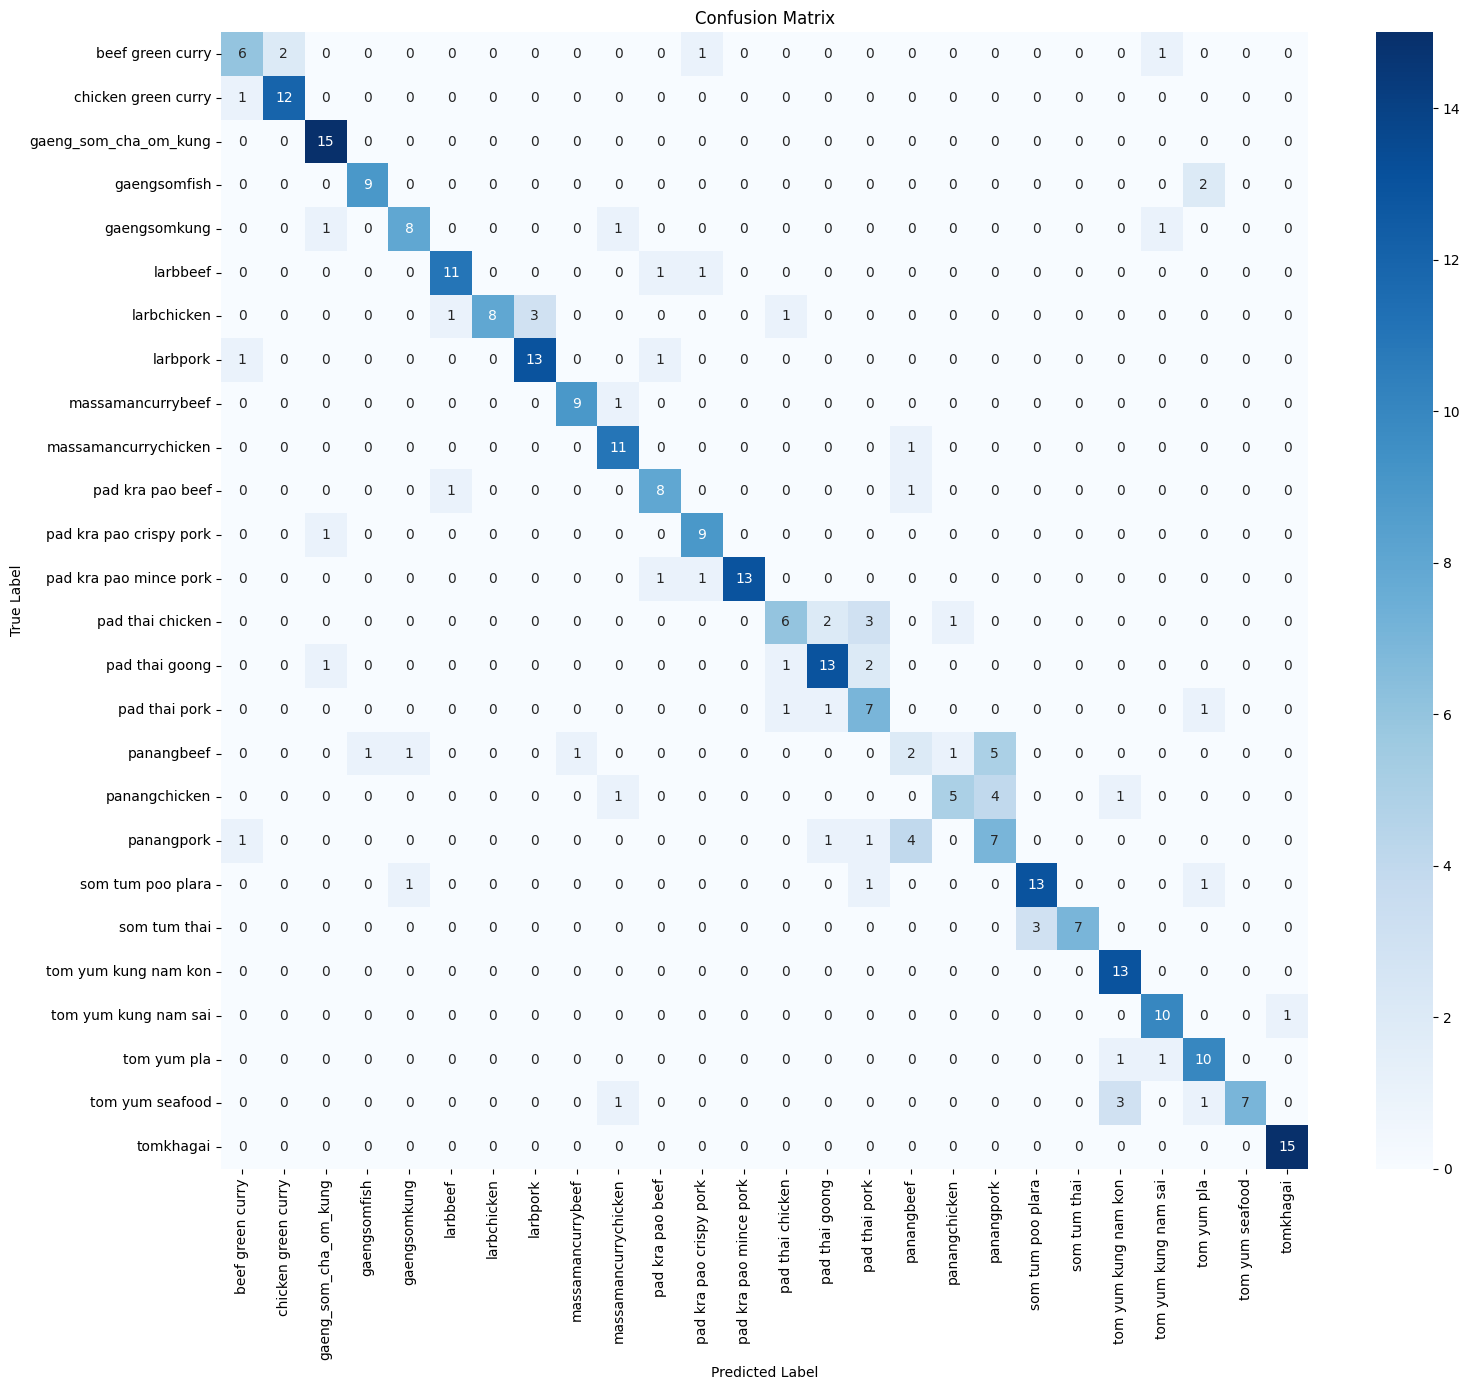

In [ ]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# สร้าง Confusion Matrix
cm = confusion_matrix(y_true, y_pred)

# แสดงผล
plt.figure(figsize=(16, 14))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Confusion Matrix')
plt.xticks(rotation=90)
plt.yticks(rotation=0)
plt.tight_layout()

plt.savefig(
    'confusion_matrix.png',
    dpi=300,
    bbox_inches='tight'
)


plt.show()

In [ ]:
from google.colab import files

files.download('confusion_matrix.png')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import numpy as np

FAMILY = {
    "beef green curry": "green curry", "chicken green curry": "green curry",
    "gaeng_som_cha_om_kung": "gaeng som", "gaengsomfish": "gaeng som", "gaengsomkung": "gaeng som",
    "larbbeef": "larb", "larbchicken": "larb", "larbpork": "larb",
    "massamancurrybeef": "massaman", "massamancurrychicken": "massaman",
    "pad kra pao beef": "pad kra pao", "pad kra pao crispy pork": "pad kra pao",
    "pad kra pao mince pork": "pad kra pao",
    "pad thai chicken": "pad thai", "pad thai goong": "pad thai", "pad thai pork": "pad thai",
    "panangbeef": "panang", "panangchicken": "panang", "panangpork": "panang",
    "som tum poo plara": "som tum", "som tum thai": "som tum",
    "tom yum kung nam kon": "tom yum", "tom yum kung nam sai": "tom yum",
    "tom yum pla": "tom yum", "tom yum seafood": "tom yum",
    "tomkhagai": "tom kha",
}

# เช็กว่าชื่อคลาสตรงกับ FAMILY ครบทุกตัว
missing = [c for c in class_names if c not in FAMILY]
assert not missing, f"ชื่อคลาสไม่ตรงกับ FAMILY: {missing}"

y_true = np.asarray(y_true)
y_pred = np.asarray(y_pred_prob).argmax(axis=1)

fam_true = np.array([FAMILY[class_names[i]] for i in y_true])
fam_pred = np.array([FAMILY[class_names[i]] for i in y_pred])

n_total = len(y_true)
n_class_ok = int((y_true == y_pred).sum())
n_family_ok = int((fam_true == fam_pred).sum())
n_within_family_err = n_family_ok - n_class_ok
n_cross_family_err = n_total - n_family_ok

print("===== Family-level summary =====")
print(f"class accuracy       : {n_class_ok}/{n_total} = {n_class_ok / n_total:.4f}")
print(f"family accuracy      : {n_family_ok}/{n_total} = {n_family_ok / n_total:.4f}")
print(f"errors within family : {n_within_family_err}")
print(f"errors cross family  : {n_cross_family_err}")

print("\n===== Per-family accuracy =====")
print(f"{'family':<14}{'family acc':>14}{'class acc':>14}")
for fam in sorted(set(FAMILY.values())):
    mask = fam_true == fam
    n = int(mask.sum())
    if n == 0:
        continue
    fam_acc = (fam_pred[mask] == fam).mean()
    cls_acc = (y_pred[mask] == y_true[mask]).mean()
    print(f"{fam:<14}{fam_acc:>14.4f}{cls_acc:>14.4f}   (n={n})")

===== Family-level summary =====
class accuracy       : 247/322 = 0.7671
family accuracy      : 291/322 = 0.9037
errors within family : 44
errors cross family  : 31

===== Per-family accuracy =====
family            family acc     class acc
gaeng som             0.8919        0.8649   (n=37)
green curry           0.9130        0.7826   (n=23)
larb                  0.8780        0.7805   (n=41)
massaman              0.9545        0.9091   (n=22)
pad kra pao           0.9143        0.8571   (n=35)
pad thai              0.9231        0.6667   (n=39)
panang                0.7778        0.3889   (n=36)
som tum               0.8846        0.7692   (n=26)
tom kha               1.0000        1.0000   (n=15)
tom yum               0.9583        0.8333   (n=48)


In [20]:
import numpy as np

MERGE = {
    "panangbeef": "panang",
    "panangchicken": "panang",
    "panangpork": "panang",
}

def merge_predictions(probs, class_names, merge=MERGE):
    """probs: (N, C) หรือ (C,) จาก model.predict -> คืน (probs ใหม่, ชื่อคลาสใหม่)"""
    probs = np.atleast_2d(probs)
    new_names = []
    for c in class_names:
        name = merge.get(c, c)
        if name not in new_names:
            new_names.append(name)
    new_probs = np.zeros((probs.shape[0], len(new_names)), dtype=probs.dtype)
    for i, c in enumerate(class_names):
        new_probs[:, new_names.index(merge.get(c, c))] += probs[:, i]
    return new_probs, new_names

# ใช้งาน
y_prob_m, class_names_m = merge_predictions(y_pred_prob, class_names)
y_true_m = np.array([class_names_m.index(MERGE.get(class_names[i], class_names[i])) for i in y_true])
y_pred_m = y_prob_m.argmax(axis=1)

In [22]:
from sklearn.metrics import classification_report
print("======= Classification Report (merged panang) =======")
print(classification_report(y_true_m, y_pred_m, target_names=class_names_m, digits=4))

======= Classification Report (merged panang) =======
                         precision    recall  f1-score   support

       beef green curry     0.7500    0.6000    0.6667        10
    chicken green curry     0.8571    0.9231    0.8889        13
  gaeng_som_cha_om_kung     0.8333    1.0000    0.9091        15
           gaengsomfish     0.9000    0.8182    0.8571        11
           gaengsomkung     0.8889    0.7273    0.8000        11
               larbbeef     0.8462    0.8462    0.8462        13
            larbchicken     1.0000    0.6154    0.7619        13
               larbpork     0.8125    0.8667    0.8387        15
      massamancurrybeef     0.9000    0.9000    0.9000        10
   massamancurrychicken     0.7333    0.9167    0.8148        12
       pad kra pao beef     0.7273    0.8000    0.7619        10
pad kra pao crispy pork     0.7500    0.9000    0.8182        10
 pad kra pao mince pork     1.0000    0.8667    0.9286        15
       pad thai chicken     0.6667 

In [24]:
import numpy as np

def predict_hierarchical(probs, class_names, family, threshold=0.7):
    probs = np.asarray(probs).ravel()
    fam_probs = {}
    for p, c in zip(probs, class_names):
        fam_probs[family[c]] = fam_probs.get(family[c], 0.0) + p
    best_fam = max(fam_probs, key=fam_probs.get)
    members = [i for i, c in enumerate(class_names) if family[c] == best_fam]
    best_sub = max(members, key=lambda i: probs[i])
    share = probs[best_sub] / fam_probs[best_fam]
    if len(members) == 1 or share >= threshold:
        return class_names[best_sub], "subclass", float(probs[best_sub])
    return best_fam, "family", float(fam_probs[best_fam])


def evaluate_hierarchical(y_true, y_prob, class_names, family, threshold):
    n = len(y_true)
    n_sub = n_sub_ok = n_fam_ok = 0
    for t, p in zip(y_true, y_prob):
        label, level, _ = predict_hierarchical(p, class_names, family, threshold)
        true_name = class_names[t]
        if level == "subclass":
            n_sub += 1
            n_sub_ok += label == true_name
        else:
            n_fam_ok += label == family[true_name]
    n_fam = n - n_sub
    print(f"th={threshold:.1f} | ตอบ subclass {n_sub:3d} รูป ({n_sub/n:.0%}) ถูก {n_sub_ok/max(n_sub,1):.3f}"
          f" | ตอบเมนูใหญ่ {n_fam:3d} รูป ถูก {n_fam_ok/max(n_fam,1):.3f}"
          f" | ถูกรวม {(n_sub_ok + n_fam_ok)/n:.3f}")


for th in [0.5, 0.6, 0.7, 0.8, 0.9]:
    evaluate_hierarchical(y_true, y_pred_prob, class_names, FAMILY, th)

th=0.5 | ตอบ subclass 316 รูป (98%) ถูก 0.782 | ตอบเมนูใหญ่   6 รูป ถูก 0.833 | ถูกรวม 0.783
th=0.6 | ตอบ subclass 291 รูป (90%) ถูก 0.797 | ตอบเมนูใหญ่  31 รูป ถูก 0.935 | ถูกรวม 0.811
th=0.7 | ตอบ subclass 275 รูป (85%) ถูก 0.811 | ตอบเมนูใหญ่  47 รูป ถูก 0.936 | ถูกรวม 0.829
th=0.8 | ตอบ subclass 242 รูป (75%) ถูก 0.855 | ตอบเมนูใหญ่  80 รูป ถูก 0.887 | ถูกรวม 0.863
th=0.9 | ตอบ subclass 201 รูป (62%) ถูก 0.896 | ตอบเมนูใหญ่ 121 รูป ถูก 0.876 | ถูกรวม 0.888


In [25]:
from tensorflow import keras
from sklearn.metrics import classification_report
import numpy as np

loaded = keras.models.load_model("food_classifier_efficientnetb0.keras")
test_loader.reset()
p = loaded.predict(test_loader)
print(classification_report(test_loader.classes, p.argmax(axis=1),
                            target_names=class_names, digits=4))

/usr/local/lib/python3.13/dist-packages/keras/src/saving/saving_lib.py:797: UserWarning: Skipping variable loading for optimizer 'rmsprop', because it has 217 variables whereas the saved optimizer has 432 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))


11/11 ━━━━━━━━━━━━━━━━━━━━ 30s 962ms/step
                         precision    recall  f1-score   support

       beef green curry     0.6667    0.6000    0.6316        10
    chicken green curry     0.8571    0.9231    0.8889        13
  gaeng_som_cha_om_kung     0.8333    1.0000    0.9091        15
           gaengsomfish     0.9000    0.8182    0.8571        11
           gaengsomkung     0.8000    0.7273    0.7619        11
               larbbeef     0.8462    0.8462    0.8462        13
            larbchicken     1.0000    0.6154    0.7619        13
               larbpork     0.8125    0.8667    0.8387        15
      massamancurrybeef     0.9000    0.9000    0.9000        10
   massamancurrychicken     0.7333    0.9167    0.8148        12
       pad kra pao beef     0.7273    0.8000    0.7619        10
pad kra pao crispy pork     0.7500    0.9000    0.8182        10
 pad kra pao mince pork     1.0000    0.8667    0.9286        15
       pad thai chicken     0.6667    0.5000   

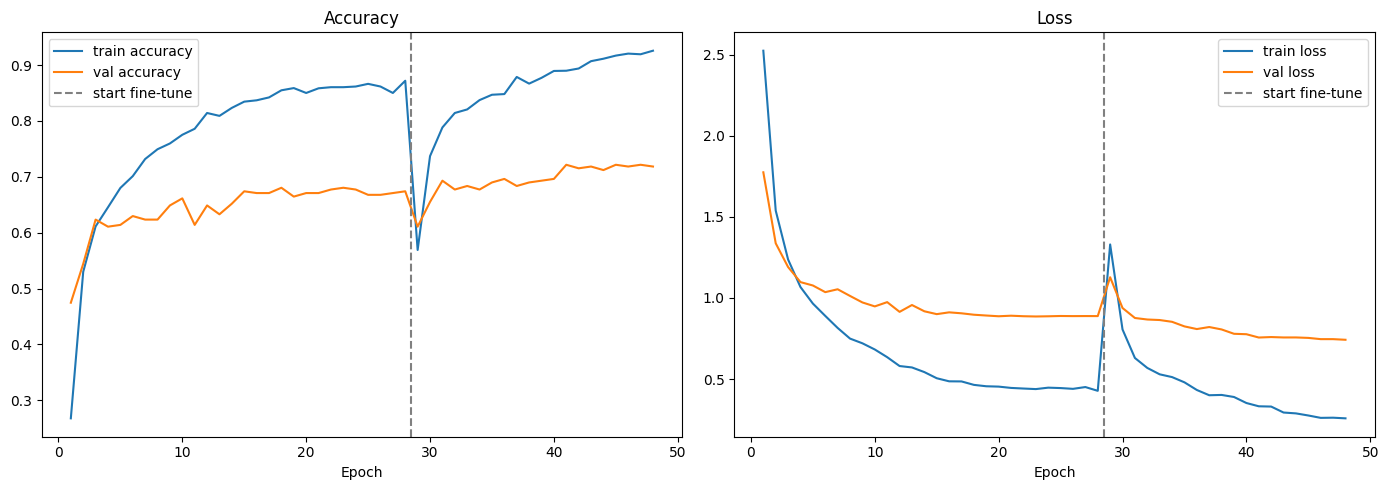

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [26]:
import json
import matplotlib.pyplot as plt
from google.colab import files

# ===== รวม history สองช่วง =====
keys = ['accuracy', 'val_accuracy', 'loss', 'val_loss']
history = {k: train_result.history[k] + fine_result.history[k] for k in keys}
history['fine_tune_start_epoch'] = len(train_result.history['accuracy'])

with open('/content/save_training_result.json', 'w') as f:
    json.dump(history, f, indent=2)

# ===== พล็อตกราฟ =====
start = history['fine_tune_start_epoch']
epochs = range(1, len(history['accuracy']) + 1)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, metric, title in [(axes[0], 'accuracy', 'Accuracy'), (axes[1], 'loss', 'Loss')]:
    ax.plot(epochs, history[metric], label=f'train {metric}')
    ax.plot(epochs, history[f'val_{metric}'], label=f'val {metric}')
    ax.axvline(start + 0.5, color='gray', linestyle='--', label='start fine-tune')
    ax.set_title(title)
    ax.set_xlabel('Epoch')
    ax.legend()

plt.tight_layout()
plt.savefig('/content/training_history.png', dpi=300, bbox_inches='tight')
plt.show()

files.download('/content/save_training_result.json')
files.download('/content/training_history.png')